# 04 · Run on a REAL Quantum Computer ⚛️☁️
### Quantum Technologies Club Workshop · *Qiskit from zero*

[▶️ Open in Colab](https://colab.research.google.com/github/quantumtechcluburi/workshops/blob/main/qiskit-from-zero-11-10-26/notebooks/04_run_on_a_real_quantum_computer.ipynb) · 📥 [All workshop materials on GitHub](https://github.com/quantumtechcluburi/workshops/tree/main/qiskit-from-zero-11-10-26)

Everything so far ran on a **simulator** on your own computer. Now we'll send a circuit to an **actual IBM quantum computer** through the cloud. It's free.

**What you need:**
1. A free **IBM Quantum Platform** account → see `SETUP_AND_SIGNUP.md` (≈5 minutes)
2. Your **API key** (a long secret string, created on the platform dashboard)

**No account yet / Wi-Fi is down?** No problem: leave `USE_REAL_HARDWARE = False` and this notebook uses a **fake backend**, a faithful copy of a real IBM chip (same layout, same noise levels) that runs on your laptop. All the cells work either way.

> ⏱️ **The free Open Plan gives you 10 minutes of quantum computer time every 28 days.** That's plenty: the circuits in this notebook use a few seconds each. But don't put a real-hardware call inside a big loop!

In [1]:
# ⚙️ SETUP: run this cell first (Shift + Enter)
# On Google Colab (or any fresh computer) this installs Qiskit automatically. Takes ~30 s the first time.
try:
    import qiskit, qiskit_aer, qiskit_ibm_runtime
except ImportError:
    %pip install -q qiskit qiskit-aer qiskit-ibm-runtime pylatexenc matplotlib ipywidgets
    import qiskit, qiskit_aer, qiskit_ibm_runtime

import numpy as np
import matplotlib.pyplot as plt
print("✅ Qiskit", qiskit.__version__, "| Aer", qiskit_aer.__version__, "| ready to go!")

✅ Qiskit 2.6.2 | Aer 0.18.2 | ready to go!


In [2]:
# 👇 THE ONE SWITCH: set to True once you have your IBM Quantum account and API key
USE_REAL_HARDWARE = False

## 1 · Why bother with real hardware? 🤔
Simulators are perfect and noise-free… but they store **2ⁿ numbers** for *n* qubits. Every extra qubit **doubles** the memory needed:

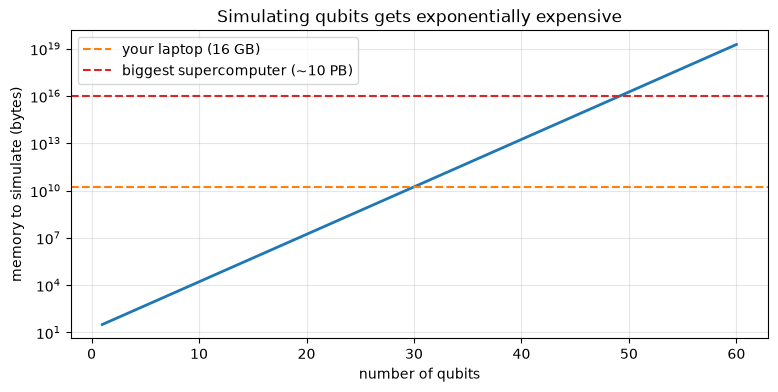

Laptop limit ≈ 29 qubits.  Supercomputer limit ≈ 49 qubits.
IBM's current chips have 100+ qubits. 🤯


In [3]:
n = np.arange(1, 61)
bytes_needed = 16 * 2.0 ** n                       # 16 bytes per complex amplitude

plt.figure(figsize=(9, 4))
plt.semilogy(n, bytes_needed, lw=2)
for label, size, colour in [("your laptop (16 GB)", 16e9, "C1"), ("biggest supercomputer (~10 PB)", 1e16, "C3")]:
    plt.axhline(size, ls="--", color=colour, label=label)
plt.xlabel("number of qubits"); plt.ylabel("memory to simulate (bytes)")
plt.title("Simulating qubits gets exponentially expensive"); plt.legend(); plt.grid(alpha=0.3, which="both")
plt.show()
print("Laptop limit ≈", int(np.log2(16e9 / 16)), "qubits.  Supercomputer limit ≈", int(np.log2(1e16 / 16)), "qubits.")
print("IBM's current chips have 100+ qubits. 🤯")

## 2 · Connect to IBM Quantum 🔑

Get your API key ready (from the **IBM Quantum Platform dashboard → Create API key**).

There are 3 safe ways to give it to Qiskit; the next cell tries them in this order:
1. **Saved on this computer** (see the optional cell below; good for your *own* laptop)
2. **Colab Secrets**: in Google Colab click the 🔑 icon on the left, add a secret named `IBM_QUANTUM_TOKEN`, paste your key, and enable notebook access
3. **Type it in**: a hidden prompt (nothing is stored)

> 🚫 **Never paste your API key directly into a code cell** that you might share, screenshot, or upload to GitHub. Treat it like a password.

In [4]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = None
if USE_REAL_HARDWARE:
    try:
        service = QiskitRuntimeService()                     # 1) previously saved account
        print("Using saved account ✅")
    except Exception:
        token = None
        try:
            from google.colab import userdata                  # 2) Colab secret
            token = userdata.get("IBM_QUANTUM_TOKEN")
            print("Using Colab secret ✅")
        except Exception:
            pass
        if not token:
            from getpass import getpass                        # 3) hidden prompt
            token = getpass("Paste your IBM Quantum API key (hidden): ").strip()
        service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token)
    print("Connected to IBM Quantum ✅")
else:
    print("Simulation mode: using a fake backend (set USE_REAL_HARDWARE = True to go real)")

Simulation mode: using a fake backend (set USE_REAL_HARDWARE = True to go real)


### (Optional) Save your account on your *own* laptop
Run this **once** on your personal computer and you'll never need to paste the key again: future notebooks just call `QiskitRuntimeService()`.
Don't do this on shared/public computers. It writes the key to `~/.qiskit/qiskit-ibm.json`.

In [5]:
# from qiskit_ibm_runtime import QiskitRuntimeService
# QiskitRuntimeService.save_account(
#     token="PASTE-YOUR-API-KEY-HERE",   # ⚠️ delete it from this cell after running!
#     set_as_default=True,
#     overwrite=True,
# )

## 3 · Pick a quantum computer 🖥️
`least_busy()` picks the available machine with the shortest queue.

In [6]:
if USE_REAL_HARDWARE:
    print("Machines you can use:", [b.name for b in service.backends()])
    backend = service.least_busy(operational=True, simulator=False)
else:
    from qiskit_ibm_runtime.fake_provider import FakeKingston
    backend = FakeKingston()          # a noisy copy of the real 'ibm_kingston' chip

print(f"👉 Using: {backend.name}  ({backend.num_qubits} qubits)")

👉 Using: fake_kingston  (156 qubits)


In [7]:
# ⏱️ How much of your free quantum time is left? (real hardware only)
if USE_REAL_HARDWARE:
    try:
        print(service.usage())
    except Exception as e:
        print("Couldn't fetch usage here; check the dashboard instead.", e)

### Meet the chip 🔬
Each circle is a physical qubit; lines show which pairs can talk to each other directly (only neighbours can do a 2-qubit gate!). Colours show the error rates: real qubits are **not all equally good**.

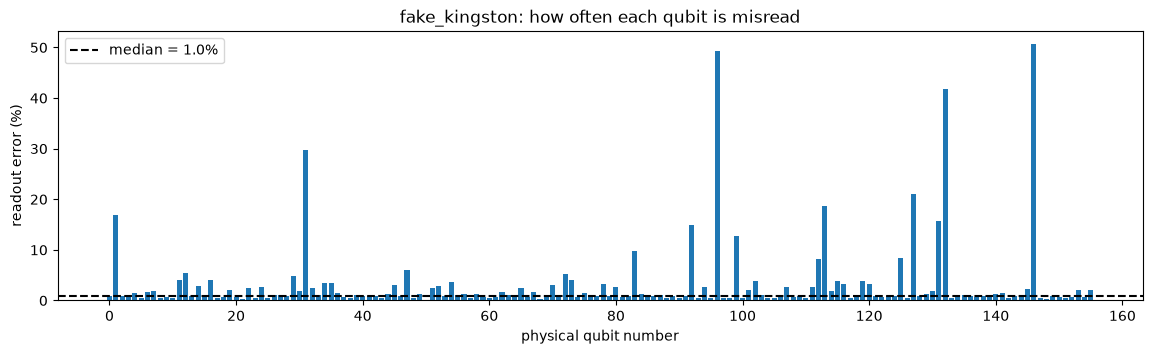

In [8]:
from qiskit.visualization import plot_error_map

try:
    display(plot_error_map(backend, figsize=(14, 9)))      # needs the Graphviz program installed
except Exception:
    plt.close("all")
    # Fallback without Graphviz: readout error of every qubit on the chip
    errs = [backend.target["measure"][(q,)].error for q in range(backend.num_qubits)]
    plt.figure(figsize=(14, 3.5))
    plt.bar(range(len(errs)), np.array(errs) * 100, color="C0")
    plt.axhline(np.median(errs) * 100, color="k", ls="--", label=f"median = {np.median(errs)*100:.1f}%")
    plt.xlabel("physical qubit number"); plt.ylabel("readout error (%)")
    plt.title(f"{backend.name}: how often each qubit is misread"); plt.legend(); plt.show()

## 4 · Build → Optimize → Run → Analyze
### 🧱 Build: our Bell state from notebook 03

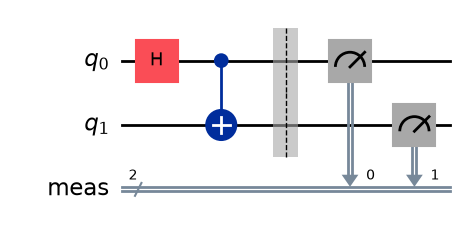

In [9]:
from qiskit import QuantumCircuit

bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)
bell.measure_all()
bell.draw("mpl")

### 🛠️ Optimize (transpile)
Real chips only understand a few **native gates** and only connect neighbouring qubits. The **transpiler** rewrites our circuit in the chip's own "language" and picks which physical qubits to use. Notice that `H` and `CX` have been replaced by other gates, and that our qubits 0 and 1 got moved to good-quality physical qubits on the chip (a higher `optimization_level` tries harder to avoid bad qubits):

Native gates this chip understands: ['cz', 'delay', 'id', 'if_else', 'measure', 'measure_2', 'reset', 'rz', 'sx', 'x']
Gate counts after transpiling     : {'rz': 5, 'sx': 3, 'measure': 2, 'cz': 1, 'barrier': 1}
Physical qubits chosen            : [21, 20] → readout errors ['0.3%', '0.7%']


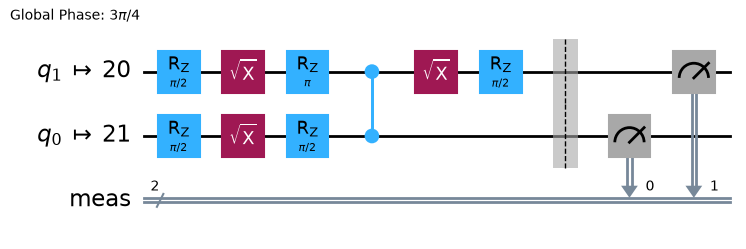

In [10]:
from qiskit.transpiler import generate_preset_pass_manager

pm = generate_preset_pass_manager(backend=backend, optimization_level=2)   # 0 = fast/dumb … 3 = slow/smart
isa_bell = pm.run(bell)            # ISA = "Instruction Set Architecture" circuit, i.e. chip-ready

used = isa_bell.layout.final_index_layout()
print("Native gates this chip understands:", sorted(backend.operation_names))
print("Gate counts after transpiling     :", dict(isa_bell.count_ops()))
print("Physical qubits chosen            :", used,
      "→ readout errors", [f"{backend.target['measure'][(q,)].error:.1%}" for q in used])
isa_bell.draw("mpl", idle_wires=False)

### ▶️ Run
The `Sampler` is the *same* idea as in notebook 02; we just point it at the backend.
On real hardware your job joins a **queue**; it can take from seconds to (on busy days) a while. You can close the notebook and fetch the result later using the job ID.

In [11]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(mode=backend)
job = sampler.run([isa_bell], shots=1000)
print("Job submitted! ID:", job.job_id())
print("Status:", job.status())

Job submitted! ID: 04909fa7-35d5-4b89-b84e-1cf599809b3c
Status: RUNNING


In [12]:
result = job.result()               # ⏳ waits for the job to finish
real_counts = result[0].data.meas.get_counts()
print(real_counts)

{'11': 506, '00': 484, '10': 5, '01': 5}


> 💡 **Lost your notebook?** On real hardware you can always get results back later:
> ```python
> job = service.job("YOUR-JOB-ID")
> job.result()[0].data.meas.get_counts()
> ```
> You can also see all your jobs on the **Workloads** page of the IBM Quantum Platform.

### 📊 Analyze: ideal vs. real

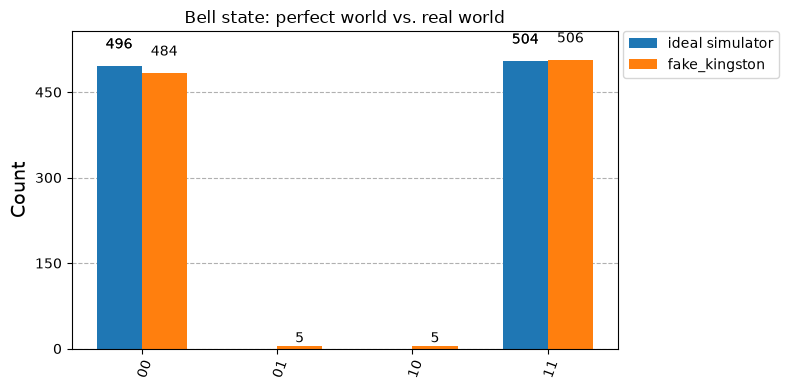

In [13]:
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram

ideal_counts = StatevectorSampler().run([bell], shots=1000).result()[0].data.meas.get_counts()
plot_histogram([ideal_counts, real_counts], legend=["ideal simulator", backend.name],
               title="Bell state: perfect world vs. real world", figsize=(8, 4))

See those small `01` and `10` bars? That's **noise**: real qubits are fragile and get disturbed by heat, stray signals and imperfect control pulses. Fighting noise (error *mitigation* and error *correction*) is one of the biggest research areas in quantum computing today.

## 5 · How does noise grow with size? 📉
Let's run GHZ states (all-○ or all-●, from notebook 03) with 2 → 10 qubits **in a single job** and measure how often we get a "correct" answer (all 0s or all 1s).

Job ID: babba17f-bb35-481d-9d84-705faf273cf8


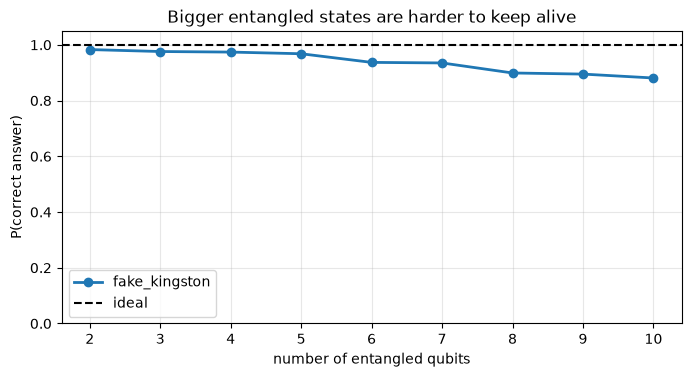

In [14]:
def ghz(n):
    qc = QuantumCircuit(n)
    qc.h(0)
    for q in range(n - 1):
        qc.cx(q, q + 1)
    qc.measure_all()
    return qc

sizes = list(range(2, 11))
isa_circuits = pm.run([ghz(n) for n in sizes])
job = sampler.run(isa_circuits, shots=1000)          # one job, 9 circuits → a few seconds of QPU time
print("Job ID:", job.job_id())
results = job.result()

success = []
for n, res in zip(sizes, results):
    counts = res.data.meas.get_counts()
    success.append((counts.get("0" * n, 0) + counts.get("1" * n, 0)) / 1000)

plt.figure(figsize=(8, 3.8))
plt.plot(sizes, success, "o-", lw=2, label=backend.name)
plt.axhline(1, color="k", ls="--", label="ideal")
plt.ylim(0, 1.05); plt.xlabel("number of entangled qubits"); plt.ylabel("P(correct answer)")
plt.title("Bigger entangled states are harder to keep alive"); plt.grid(alpha=0.3); plt.legend()
plt.show()

---
## 🎉 You did it!
You just programmed a quantum computer. Here's your **"I can now…"** checklist:

- [x] Explain a qubit as an arrow on the Bloch sphere
- [x] Use gates (`x`, `h`, `z`, `ry`, `cx` …) to move qubits around
- [x] Measure circuits on a simulator and plot histograms
- [x] Create superposition, interference and entanglement
- [x] Run a circuit on a real IBM quantum computer and see the noise

## 🚀 Where to go next
| Resource | What it is |
|---|---|
| [IBM Quantum Platform](https://quantum.cloud.ibm.com) | Your account, API key, jobs and machines |
| [IBM Quantum Composer](https://quantum.cloud.ibm.com/composer) | Build circuits by **drag-and-drop** in the browser, no code |
| [IBM Quantum Learning](https://quantum.cloud.ibm.com/learning) | Free courses: start with *Basics of Quantum Information* |
| [Qiskit documentation](https://quantum.cloud.ibm.com/docs) | Guides, tutorials and API reference |
| [Qiskit on GitHub](https://github.com/Qiskit/qiskit) | The open-source code (contributions welcome!) |
| [Workshop materials](https://github.com/quantumtechcluburi/workshops) | These notebooks + quick reference: download them to keep practising |

### Ideas to try at home
* Re-run notebook 02's **interference fringes** on real hardware (one job with all the phases!) and compare with the simulator.
* Build the **12-ball GHZ** from notebook 03 on a real chip: how many "wrong" answers appear?
* Re-create the Bell state in the **Composer** by dragging gates and compare the generated Python code with ours.